In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def load_dataset(filename):
    BASE_DIR = './data'
    EXTENSION = '.csv'
    TARGET_PATH = f'{BASE_DIR}/{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding = 'euc-kr')

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

df = pd.read_csv("../data/port_month.csv", encoding="cp949")

# 연간 하역능력 (단위: 천TEU)
annual_capacity = pd.Series({
    "신항1부두": 2090,
    "신항2부두": 3790,
    "신항3부두": 2310,
    "신항4부두": 1930,
    "신항5부두": 2440,
    # "신항6부두": 1950,
    # "신항7부두": 1950,
})

# 기준년도와 월을 날짜로 변환
df["기준연월"] = pd.to_datetime({
    "year": df["기준년도"],
    "month": df["월"],
    "day": 1,
})

# 분석 기간 선택
df = df[
    df["기준연월"].between("2022-01-01", "2025-12-01")
].copy()

# 기준을 정할 부두
df = df[['기준연월','기준년도','월','신항1부두','신항2부두','신항3부두','신항4부두','신항5부두']]


In [ ]:

# 1. record
record = pd.read_csv(
    "../data/record_except_168.csv",
    encoding="utf-8-sig",
)

# 2. 선박별 재항시간 계산
record["입항일시"] = pd.to_datetime(
    record["입항일시"], errors="coerce"
)
record["출항일시"] = pd.to_datetime(
    record["출항일시"], errors="coerce"
)

record["재항시간_h"] = (
    record["출항일시"] - record["입항일시"]
).dt.total_seconds() / 3600

# 쉼표가 포함된 총톤수를 숫자로 변환
record["총톤수_num"] = pd.to_numeric(
    record["총톤수"].astype(str).str.replace(",", "", regex=False),
    errors="coerce",
)

# 계선장소에서 부두 번호 추출
record["부두번호"] = record["계선장소"].str.extract(
    r"신항\s*(\d+)\s*부두"
)[0]

record["기준연월"] = record["입항일시"].dt.strftime("%Y-%m")

# 분석 기간과 유효한 기록 선택
record = record[
    record["입항일시"].ge("2022-01-01")
    & record["입항일시"].lt("2026-01-01")
    & record["재항시간_h"].ge(0)
    & record["총톤수_num"].gt(0)
    & record["부두번호"].isin(["1", "2", "3", "4", "5"])
].copy()

record

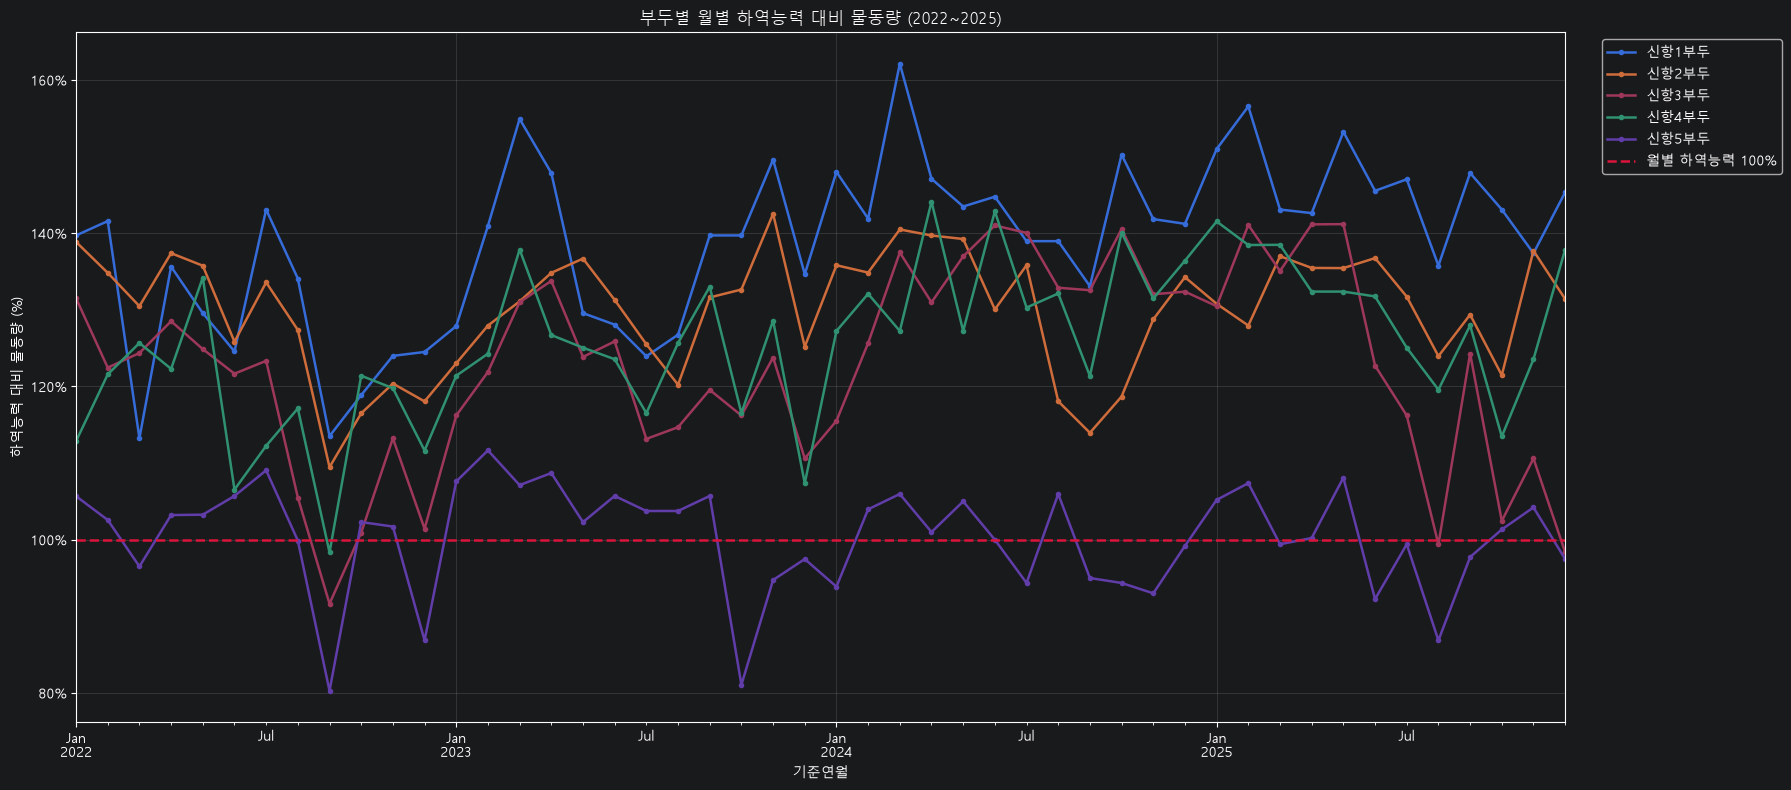

In [5]:

# 월별 물동량: 행은 기준연월, 열은 부두
monthly_volume = (
    df.set_index("기준연월")[annual_capacity.index]
      .sort_index()
      .reindex(pd.date_range("2022-01-01", "2025-12-01", freq="MS"))
)
monthly_volume.index.name = "기준연월"

# 각 월의 일수와 해당 연도의 총일수
month_days = pd.Series(
    monthly_volume.index.days_in_month,
    index=monthly_volume.index,
)

year_days = pd.Series(
    365 + monthly_volume.index.is_leap_year.astype(int),
    index=monthly_volume.index,
)

# 월별 하역능력 = 연간 하역능력 × 월 일수 / 연 일수
monthly_capacity = pd.DataFrame(
    1.0,
    index=monthly_volume.index,
    columns=annual_capacity.index,
).mul(annual_capacity, axis="columns").mul(
    month_days / year_days,
    axis="index",
)

# 월별 하역능력 대비 물동량 비율 (%)
ratio_table = monthly_volume.div(monthly_capacity).mul(100)

# # 5개 부두를 한 그래프에 표시
# ax = ratio_table.plot.bar(
#     figsize=(18, 8),
# )

# # 5개 부두를 한 그래프에 표시
ax = ratio_table.plot(
    figsize=(18, 8),
    marker="o",
    markersize=3,
    linewidth=1.8,
)

ax.axhline(
    100,
    color="crimson",
    linestyle="--",
    linewidth=1.8,
    label="월별 하역능력 100%",
)

ax.set_title("부두별 월별 하역능력 대비 물동량 (2022~2025)")
ax.set_xlabel("기준연월")
ax.set_ylabel("하역능력 대비 물동량 (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.grid(alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

# 계산 결과 확인
# print("월별 하역능력 (천TEU)")
# display(monthly_capacity.round(2))
#
# print("월별 하역능력 대비 물동량 (%)")
# display(ratio_table.round(2))

In [7]:
## x값 부두활용률 / y값 재항시간

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

record = pd.read_csv("../data/record_except_168.csv", encoding="utf-8-sig")

record["입항일시"] = pd.to_datetime(record["입항일시"], errors="coerce")
record["출항일시"] = pd.to_datetime(record["출항일시"], errors="coerce")

# 재항시간: 시간 단위
record["재항시간_h"] = (
    record["출항일시"] - record["입항일시"]
).dt.total_seconds() / 3600

# '신항 1부두 1선석' → '신항1부두'
record["부두"] = (
    record["계선장소"]
    .str.extract(r"신항\s*(\d+)\s*부두")[0]
    .map(lambda x: f"신항{x}부두" if pd.notna(x) else None)
)

# 입항한 월을 기준으로 집계
record["기준연월"] = (
    record["입항일시"].dt.to_period("M").dt.to_timestamp()
)

record = record[
    record["입항일시"].ge("2022-01-01")
    & record["입항일시"].lt("2026-01-01")
    & record["재항시간_h"].ge(0)
].copy()

# 부두별 월평균 재항시간
monthly_stay = (
    record.groupby(["기준연월", "부두"])["재항시간_h"]
          .mean()
          .unstack("부두")
)

# 두 자료에 공통으로 존재하는 부두만 비교
piers = ratio_table.columns.intersection(monthly_stay.columns)

utilization = ratio_table[piers].sort_index()
monthly_stay = monthly_stay.reindex(
    index=utilization.index,
    columns=piers,
)

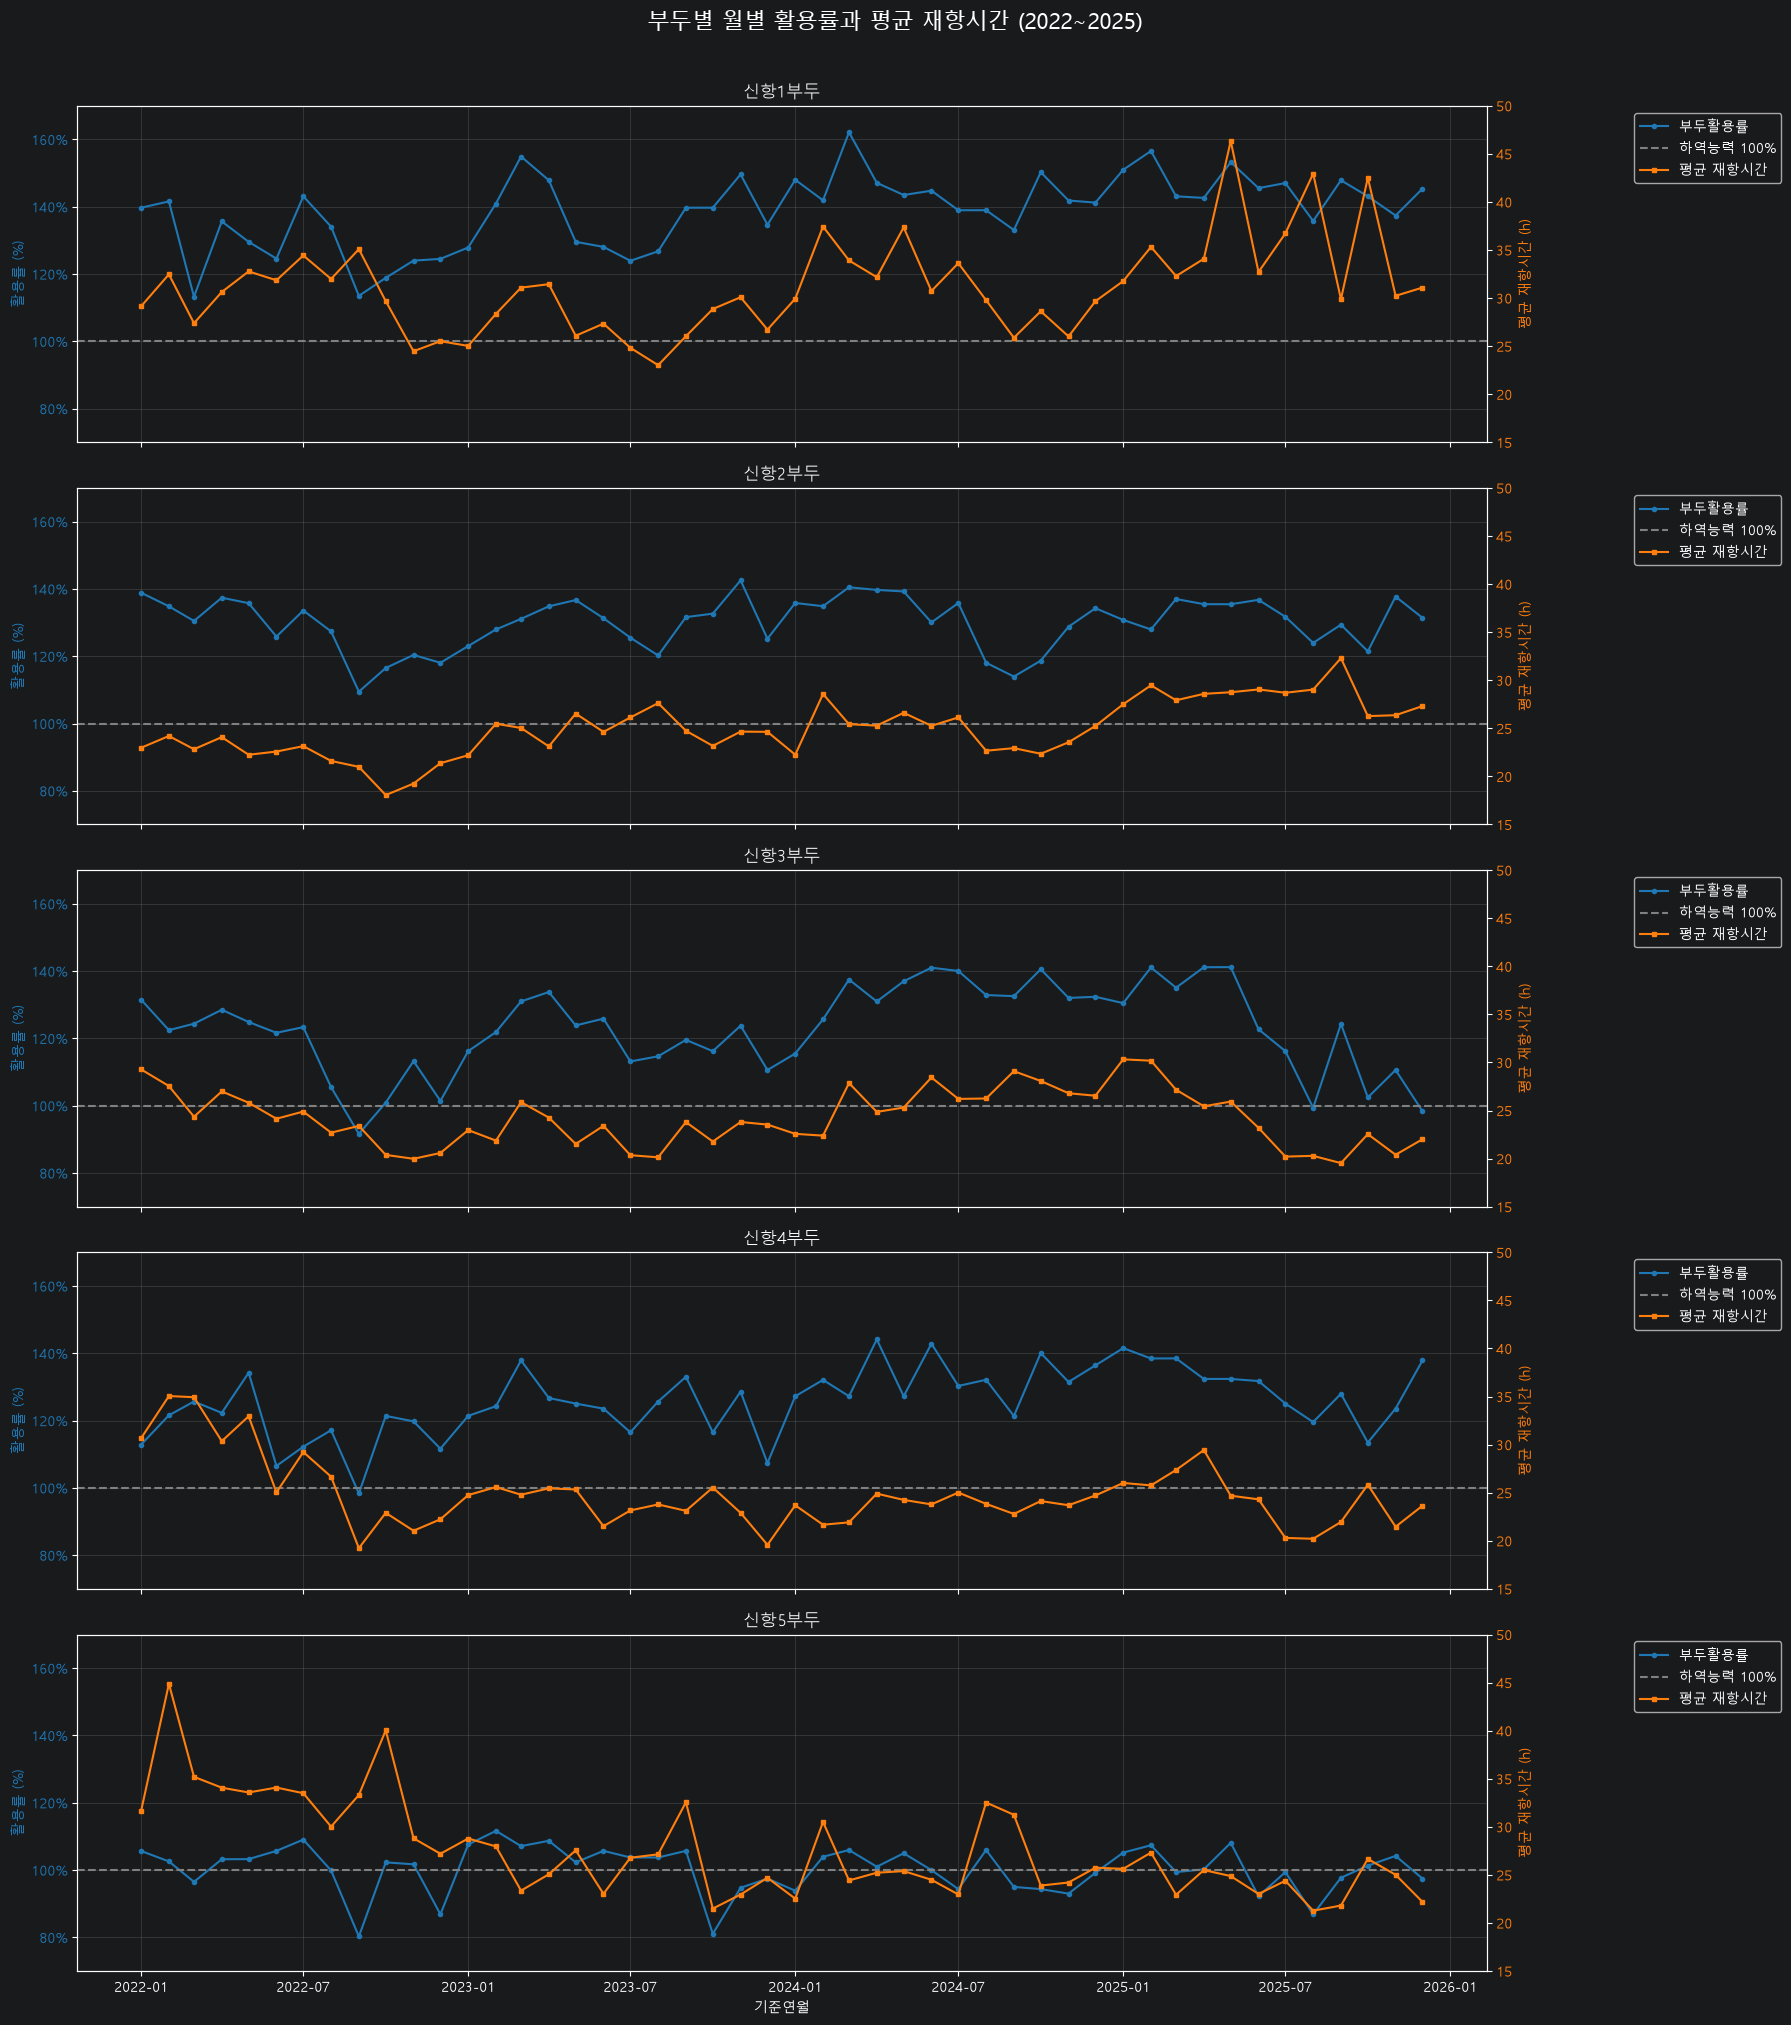

In [23]:
fig, axes = plt.subplots(
    len(piers), 1,
    figsize=(18, 4 * len(piers)),
    sharex=True,
    squeeze=False,
)

for ax, pier in zip(axes[:, 0], piers):
    # 왼쪽 축: 활용률
    ax.plot(
        utilization.index,
        utilization[pier],
        color="tab:blue",
        marker="o",
        markersize=3,
        label="부두활용률",
    )

    ax.axhline(
        100,
        color="gray",
        linestyle="--",
        label="하역능력 100%",
    )

    ax.set_ylabel("활용률 (%)", color="tab:blue")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(axis="y", labelcolor="tab:blue")
    ax.grid(alpha=0.25)

    # 오른쪽 축: 평균 재항시간
    ax_right = ax.twinx()

    ax_right.plot(
        monthly_stay.index,
        monthly_stay[pier],
        color="tab:orange",
        marker="s",
        markersize=3,
        label="평균 재항시간",
    )

    ax_right.set_ylabel("평균 재항시간 (h)", color="tab:orange")
    ax_right.tick_params(axis="y", labelcolor="tab:orange")

    ax.set_title(pier)

    # 양쪽 축의 범례 합치기
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax_right.get_legend_handles_labels()

    ax.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper left",
        bbox_to_anchor=(1.10, 1),
    )

    ax.set_ylim(70, 170)  # 왼쪽 Y축: 활용률 0~200%
    ax_right.set_ylim(15, 50)   # 오른쪽 Y축: 평균 재항시간 0~60시간

axes[-1, 0].set_xlabel("기준연월")


fig.suptitle(
    "부두별 월별 활용률과 평균 재항시간 (2022~2025)",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()
plt.show()

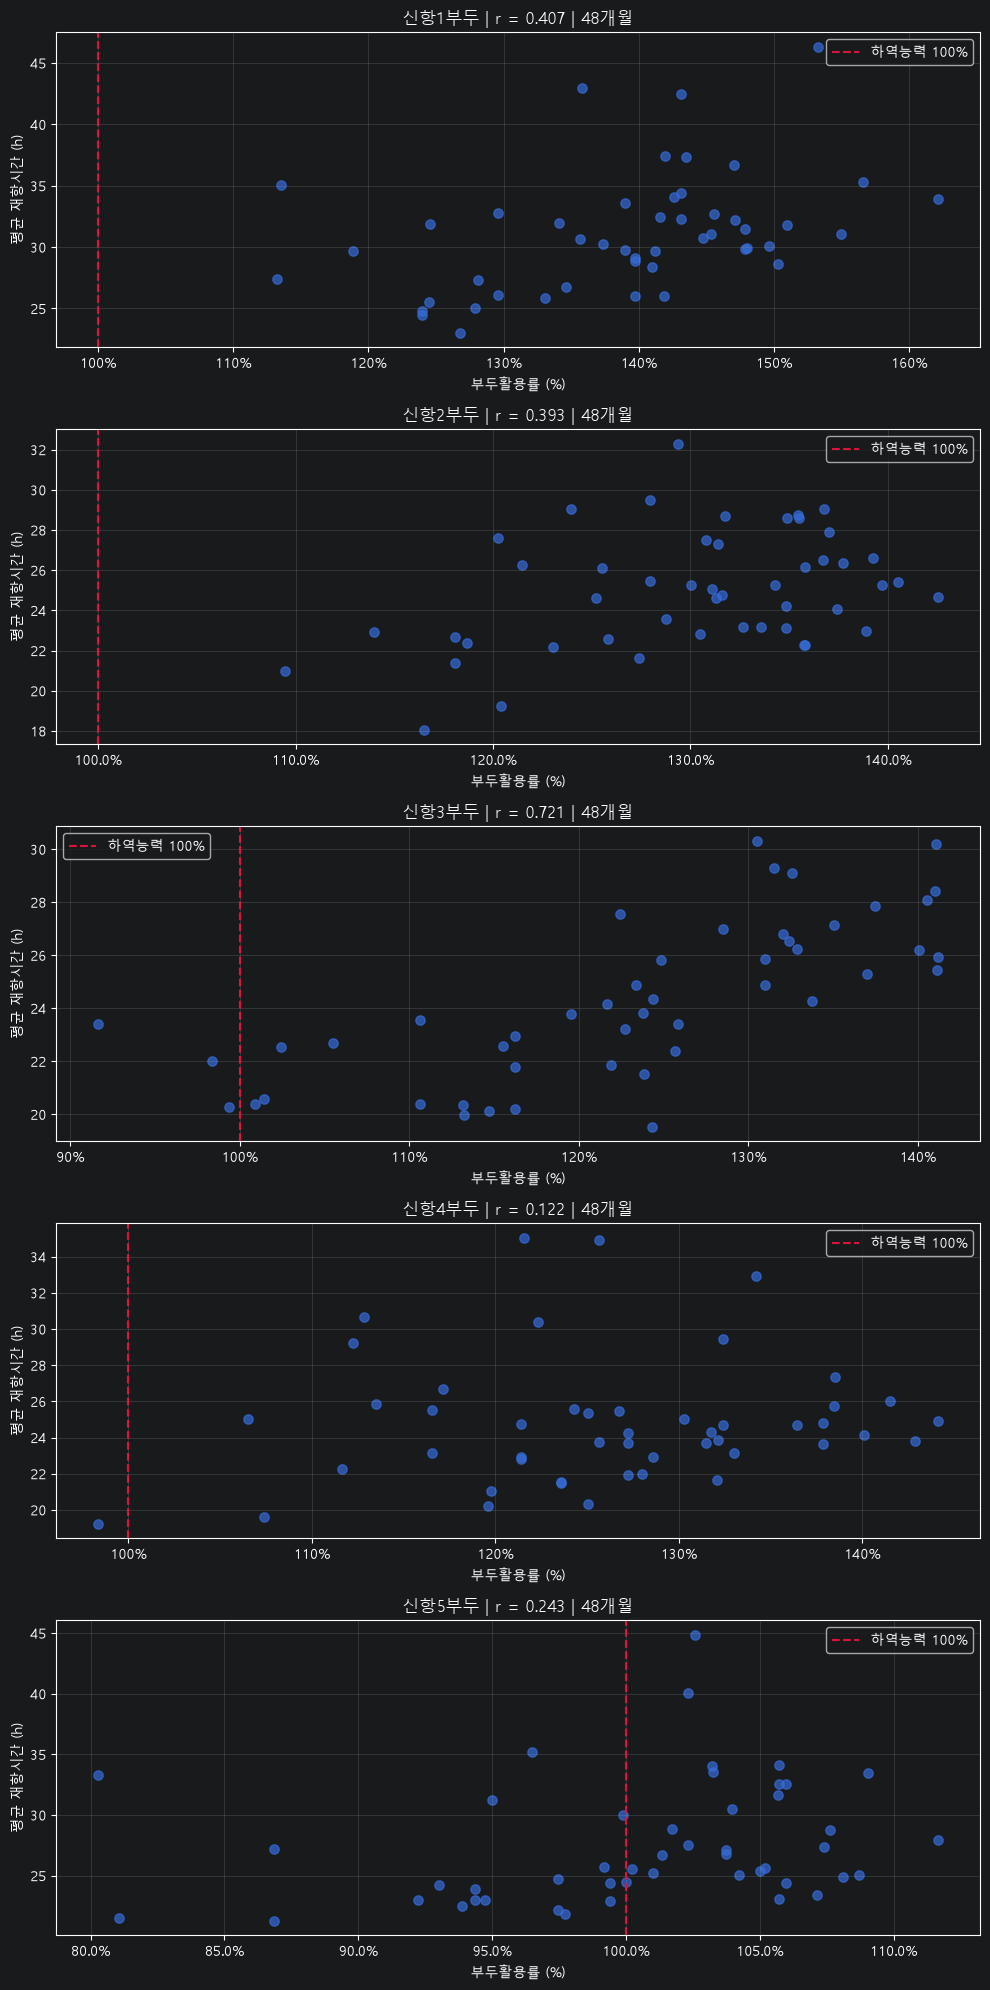

In [13]:
fig, axes = plt.subplots(
    len(piers), 1,
    figsize=(10, 4 * len(piers)),
    squeeze=False,
)

for ax, pier in zip(axes[:, 0], piers):
    # 같은 월끼리 연결하고 결측값 제외
    pair = pd.concat(
        [
            utilization[pier].rename("활용률"),
            monthly_stay[pier].rename("평균재항시간"),
        ],
        axis=1,
    ).dropna()

    r = pair["활용률"].corr(pair["평균재항시간"])

    ax.scatter(
        pair["활용률"],
        pair["평균재항시간"],
        alpha=0.7,
        s=45,
    )

    ax.axvline(
        100,
        color="crimson",
        linestyle="--",
        label="하역능력 100%",
    )

    ax.set_title(f"{pier} | r = {r:.3f} | {len(pair)}개월")
    ax.set_xlabel("부두활용률 (%)")
    ax.set_ylabel("평균 재항시간 (h)")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))

    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 기존 record, utilization, piers 사용
plot_record = record.copy()

# 총톤수를 숫자로 변환
plot_record["총톤수_num"] = pd.to_numeric(
    plot_record["총톤수"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
    errors="coerce",
)

# 총톤수 구간 설정: 필요하면 경계값 변경
tonnage_labels = [
    "3만 GT 미만",
    "3만~5만 GT 미만",
    "5만~10만 GT 미만",
    "10만 GT 이상",
]

plot_record["총톤수구간"] = pd.cut(
    plot_record["총톤수_num"],
    bins=[0, 30_000, 50_000, 100_000, np.inf],
    labels=tonnage_labels,
    right=False,
)

# 부두·총톤수 구간·월별 평균 재항시간과 기록 수
monthly_by_size = (
    plot_record.groupby(
        ["부두", "총톤수구간", "기준연월"],
        observed=True,
    )
    .agg(
        평균재항시간=("재항시간_h", "mean"),
        기록수=("재항시간_h", "size"),
    )
    .reset_index()
)

fig, axes = plt.subplots(
    len(piers),
    len(tonnage_labels),
    figsize=(25, 4 * len(piers)),
    sharex=True,
    squeeze=False,
)

for row, pier in enumerate(piers):

    for col, size_group in enumerate(tonnage_labels):
        ax = axes[row, col]

        selected = monthly_by_size[
            (monthly_by_size["부두"] == pier)
            & (monthly_by_size["총톤수구간"] == size_group)
        ]

        stay = (
            selected.set_index("기준연월")["평균재항시간"]
                    .reindex(utilization.index)
        )

        # 왼쪽 축: 해당 부두 전체의 활용률
        ax.plot(
            utilization.index,
            utilization[pier],
            color="tab:blue",
            linewidth=1.5,
            label="부두 전체 활용률",
        )

        ax.axhline(
            100,
            color="gray",
            linestyle="--",
            label="하역능력 100%",
        )

        ax.set_ylim(70, 170)  # 왼쪽 Y축: 활용률 0~200%
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
        ax.set_ylabel("활용률 (%)", color="tab:blue")
        ax.tick_params(axis="y", labelcolor="tab:blue")
        ax.grid(alpha=0.25)

        # 오른쪽 축: 해당 총톤수 구간의 평균 재항시간
        ax_right = ax.twinx()

        ax_right.plot(
            stay.index,
            stay,
            color="tab:orange",
            marker="o",
            markersize=3,
            linewidth=1.5,
            label="구간별 평균 재항시간",
        )

        ax_right.set_ylim(5, 70)   # 오른쪽 Y축: 평균 재항시간 0~60시간
        # 모든 패널에서 재항시간 축 범위 통일
        ax_right.set_ylabel("평균 재항시간 (h)", color="tab:orange")
        ax_right.tick_params(axis="y", labelcolor="tab:orange")

        n = int(selected["기록수"].sum())
        ax.set_title(f"{pier} · {size_group}\n입항기록 {n:,}건")

        if stay.notna().sum() == 0:
            ax.text(
                0.5, 0.5, "해당 구간 기록 없음",
                transform=ax.transAxes,
                ha="center",
                va="center",
            )

        # 첫 번째 패널에만 범례 표시
        if row == 0 and col == 0:
            lines1, labels1 = ax.get_legend_handles_labels()
            lines2, labels2 = ax_right.get_legend_handles_labels()
            ax.legend(
                lines1 + lines2,
                labels1 + labels2,
                fontsize=8,
                loc="upper left",
            )

        if row == len(piers) - 1:
            ax.set_xlabel("기준연월")

fig.suptitle(
    "부두·총톤수 구간별 가동률과 월평균 재항시간 (2022~2025)",
    fontsize=18,
    y=1.01,
)

plt.tight_layout()
plt.show()